## Project IND320 - Part 2 
Name: Abisan Sagayathasan 

 Github: Abisan-s , direct link: https://github.com/Abisan-s/IND320-reservoir-dashboard


 Streamlit link: https://ind320-reservoir-dashboard-ogxrr3mcdcp4x3bijhecfy.streamlit.app/

 Panopto link: 

In [1]:
#cheks if the connection to cassandra works
from cassandra.cluster import Cluster

cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect()

print("Connected to Cassandra!")

Connected to Cassandra!


In [2]:
#creates a keyspace for testing the spark to cassandra connection
session.execute("""
CREATE KEYSPACE IF NOT EXISTS my_first_keyspace
WITH REPLICATION = {
    'class': 'SimpleStrategy',
    'replication_factor': 1
};
""")

session.set_keyspace("my_first_keyspace")

#creates a simple test table
session.execute("""
CREATE TABLE IF NOT EXISTS table_with_uuid (
    id timeuuid PRIMARY KEY,
    company text,
    model text,
    price float
);
""")

#some test data
session.execute("""
INSERT INTO table_with_uuid (id, company, model, price)
VALUES (now(), 'Tesla', 'Model S', 20000.0);
""")

session.execute("""
INSERT INTO table_with_uuid (id, company, model, price)
VALUES (now(), 'Polestar', '3', 45000.0);
""")

print("Test data inserted into Cassandra")

Test data inserted into Cassandra


In [3]:
#checks if the spark connection works and that the version is correct
import os

os.environ["HADOOP_HOME"] = "C:/Hadoop/hadoop-3.3.1"
os.environ["PYSPARK_HADOOP_VERSION"] = "without"
os.environ["PYSPARK_PYTHON"] = "python"
os.environ["PYSPARK_DRIVER_PYTHON"] = "python"

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("SparkCassandraApp") \
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    ) \
    .config("spark.cassandra.connection.host", "localhost") \
    .config(
        "spark.sql.extensions",
        "com.datastax.spark.connector.CassandraSparkExtensions"
    ) \
    .config(
        "spark.sql.catalog.mycatalog",
        "com.datastax.spark.connector.datasource.CassandraCatalog"
    ) \
    .config("spark.cassandra.connection.port", "9042") \
    .getOrCreate()

print("Spark version:", spark.version)

Spark version: 3.5.1


In [4]:
#read the cassandra table with spark
test_df = spark.read \
    .format("org.apache.spark.sql.cassandra") \
    .options(
        table="table_with_uuid",
        keyspace="my_first_keyspace"
    ) \
    .load()

test_df.show()

+--------------------+--------+-------+-------+
|                  id| company|  model|  price|
+--------------------+--------+-------+-------+
|4d4ced00-cc90-11f...|   Tesla|Model S|20000.0|
|a37fe970-cc13-11f...|   Tesla|Model S|20000.0|
|4d550350-cc90-11f...|Polestar|      3|45000.0|
|a384f280-cc13-11f...|Polestar|      3|45000.0|
+--------------------+--------+-------+-------+



In [5]:
#this part checks if python and mongodb can communicate
import os
from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv(override=True)

mongo_uri = os.getenv("MONGODB_URI")

client = MongoClient(mongo_uri)
db = client["ind320"]
collection = db["test"]

collection.insert_one({"message": "MongoDB connection works"})

print(collection.find_one())

{'_id': ObjectId('6ad6ac8597d76ae16da3231d'), 'message': 'MongoDB connection works'}


## Reservoirstatistic API
- Here we get the API from Swagger UI (statistics from NVE)

In [6]:
import requests
import pandas as pd

url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url, timeout=30)
response.raise_for_status()

reservoir_data = response.json()

df = pd.DataFrame(reservoir_data)

df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


As we can see this is exact as the same as the csv file from part1

In [7]:
#renaming to the same english names used in part 1
df = df.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "year",
    "iso_uke": "week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_level_previous_week",
    "endring_fyllingsgrad": "change_in_fill_level"
})

# convert dates
df["date"] = pd.to_datetime(df["date"])
df["next_publication_date"] = pd.to_datetime(
    df["next_publication_date"],
    errors="coerce"
)

# sort chronologically
df = df.sort_values("date")

df.info()

<class 'pandas.DataFrame'>
Index: 14922 entries, 3111 to 14921
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      14922 non-null  datetime64[us]
 1   area_type                 14922 non-null  str           
 2   area_number               14922 non-null  int64         
 3   year                      14922 non-null  int64         
 4   week                      14922 non-null  int64         
 5   fill_level                14922 non-null  float64       
 6   capacity_TWh              14922 non-null  float64       
 7   stored_energy_TWh         14922 non-null  float64       
 8   next_publication_date     14922 non-null  datetime64[us]
 9   fill_level_previous_week  14922 non-null  float64       
 10  change_in_fill_level      14922 non-null  float64       
dtypes: datetime64[us](2), float64(5), int64(3), str(1)
memory usage: 1.4 MB


In [ ]:
#visually see if the names got changed and the values got sorted
df.head()

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level
3111,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,1-01-01,0.614288,0.002160
11344,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,1-01-01,0.744693,-0.135837
11170,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,1-01-01,0.661432,-0.094525
14499,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,1-01-01,0.756482,-0.121041
9678,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,1-01-01,0.752631,-0.144643


In [ ]:
#the user must be able to choose between the different areas. here i get the area API.
areas_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmråder"

areas_response = requests.get(areas_url, timeout=30)
areas_response.raise_for_status()

areas = areas_response.json()

areas

[{'land': [{'navn': 'Norge',
    'navn_langt': 'Norge',
    'beskrivelse': 'Hele landet',
    'omrType': 'NO',
    'omrnr': 0}],
  'elspot': [{'navn': 'NO 1',
    'navn_langt': 'Elspotområde 1',
    'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).',
    'omrType': 'EL',
    'omrnr': 1},
   {'navn': 'NO 2',
    'navn_langt': 'Elspotområde 2',
    'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.',
    'omrType': 'EL',
    'omrnr': 2},
   {'navn': 'NO 3',
    'navn_langt': 'Elspotområde 3',
    'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.',
    'omrType': 'EL',
    'omrnr': 3},
   {'navn': 'NO 4',
    'navn_langt': 'Elspotområde 4',
    'beskrivelse': 'Nord-Norge. Omfatter resten av

From the HentOmråde API we get information about the areas and their structure. Now we can clean up and make the data easier to understand and work with

In [10]:
#make the area information easier to work with later 
area_rows = []

for group_name, group_list in areas[0].items():
    for area in group_list:
        area_rows.append({
            "group": group_name,
            "name": area["navn"],
            "long_name": area["navn_langt"],
            "area_type": area["omrType"],
            "area_number": area["omrnr"]
        })

areas_df = pd.DataFrame(area_rows)

areas_df

,group,name,long_name,area_type,area_number
0,land,Norge,Norge,NO,0
1,elspot,NO 1,Elspotområde 1,EL,1
2,elspot,NO 2,Elspotområde 2,EL,2
3,elspot,NO 3,Elspotområde 3,EL,3
4,elspot,NO 4,Elspotområde 4,EL,4
5,elspot,NO 5,Elspotområde 5,EL,5
6,vassdrag,VASS1,Vassdragsområde 1,VASS,1
7,vassdrag,VASS2,Vassdragsområde 2,VASS,2
8,vassdrag,VASS3,Vassdragsområde 3,VASS,3
9,vassdrag,VASS4,Vassdragsområde 4,VASS,4


## Plots with API-data
- In this part i am going to recreate the plots in part 1, but with API-data rather than csv

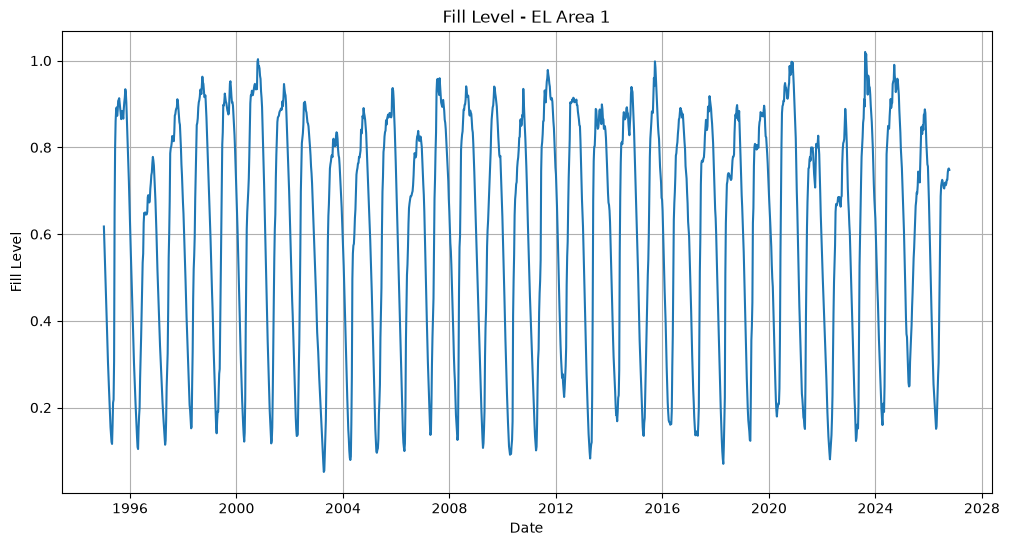

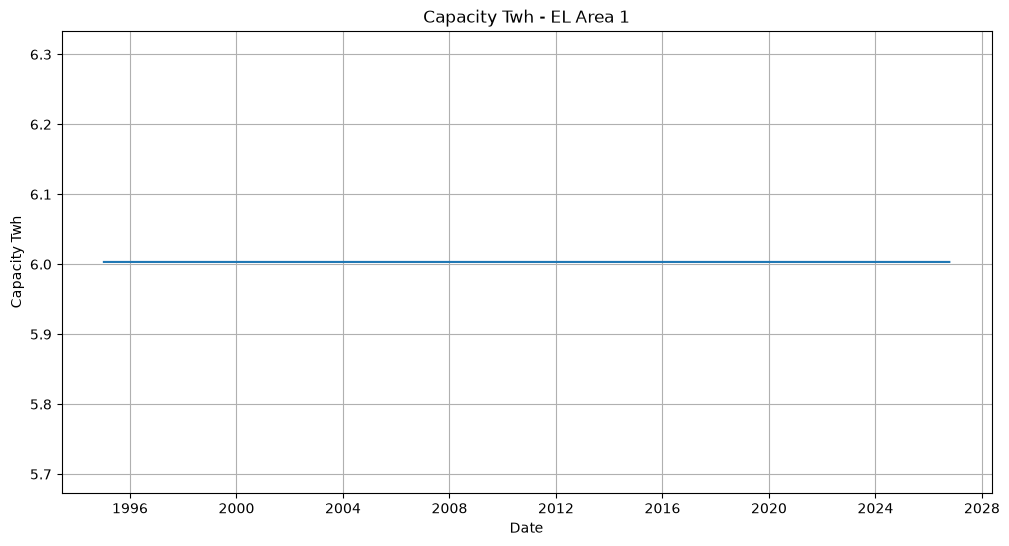

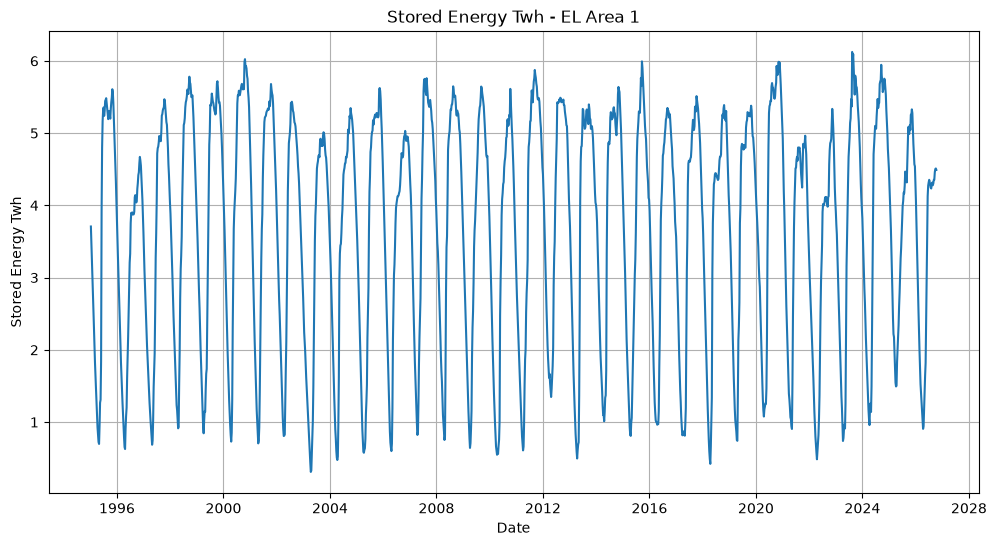

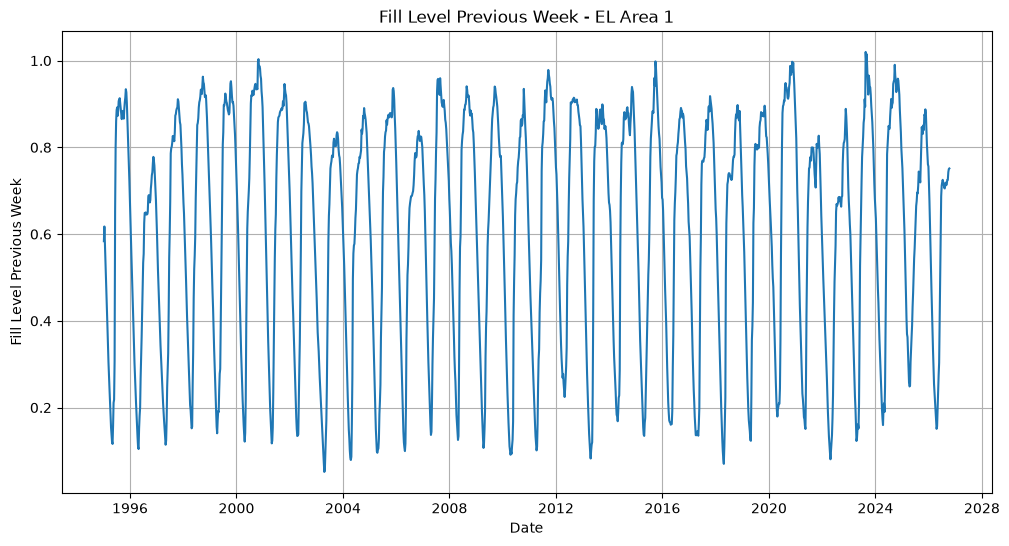

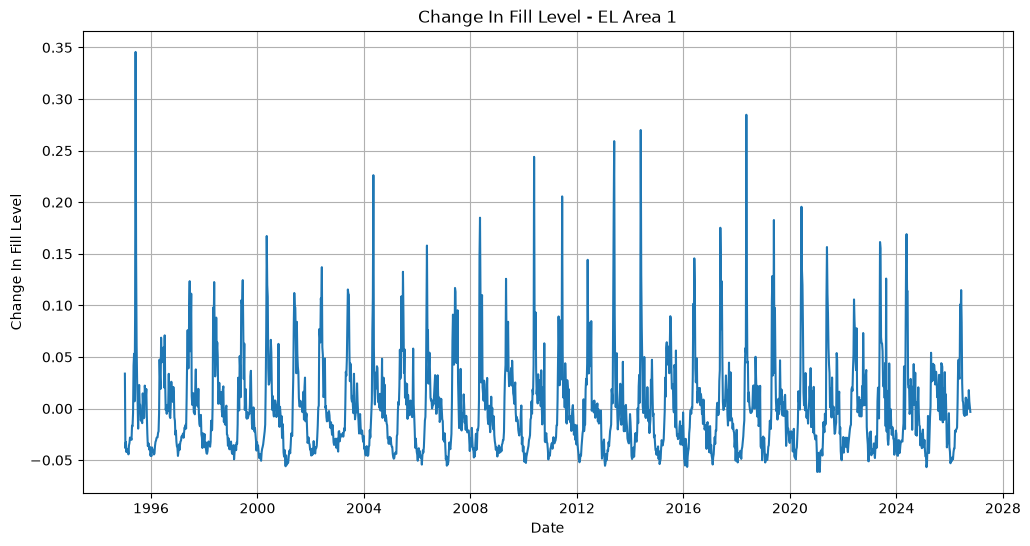

In [13]:
#this part makes a plot each for the fill level, capacity in TWh, the stored energy in TWh, the previous weeks fill level and the change in fill level
import matplotlib.pyplot as plt

plot_columns = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_level_previous_week",
    "change_in_fill_level"
]

area_data = df[
    (df["area_type"] == "EL") &
    (df["area_number"] == 1)
].copy()

for column in plot_columns:
    plt.figure(figsize=(12, 6))

    plt.plot(
        area_data["date"],
        area_data[column]
    )

    plt.title(
        f"{column.replace('_', ' ').title()} - EL Area 1"
    )
    plt.xlabel("Date")
    plt.ylabel(column.replace("_", " ").title())
    plt.grid(True)

    plt.show()

As we can see the plots have sucessfully been created with API-data. Now we can make a normalized plot to combine these datas. 

capacity_TWh is constant and is not included in the normalized plot.


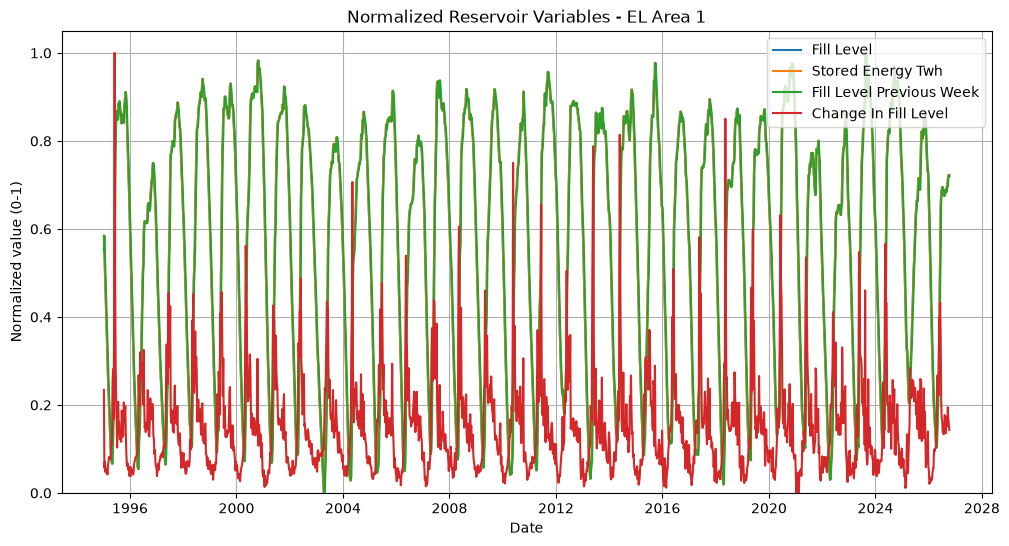

In [16]:
#variables we want to compare
plot_columns = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_level_previous_week",
    "change_in_fill_level"
]

normalized_data = area_data[plot_columns].copy()

columns_to_plot = []

for column in plot_columns:
    minimum = normalized_data[column].min()
    maximum = normalized_data[column].max()

    #this part only normalizs the variables that change over time
    if maximum != minimum:
        normalized_data[column] = (
            normalized_data[column] - minimum
        ) / (maximum - minimum)

        columns_to_plot.append(column)
    else:
        print(f"{column} is constant and is not included in the normalized plot.") #capacity TWh is always the same, so its not necassary to include it here

plt.figure(figsize=(12, 6))

for column in columns_to_plot:
    plt.plot(
        area_data["date"],
        normalized_data[column],
        label=column.replace("_", " ").title()
    )

plt.title("Normalized Reservoir Variables - EL Area 1")
plt.xlabel("Date")
plt.ylabel("Normalized value (0-1)")
plt.ylim(0, 1.05)
plt.legend(loc="upper right")
plt.grid(True)

plt.show()

As we can see the variables were normalized successfully with API-data. They are normalized between 0 and 1 to make them easier to compare. Capacity is excluded because it is constant for this area. Fill level, stored energy and previous week fill level follow similar seasonal patterns, while change in fill level shows shorter-term weekly variations.

## ENTSO-E API 
- Per now i dont have the token yet, but this will be fixed when i get it. I have made the structure ready by doing research and with AI so that i can finish it ASAP

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)

#gets the entsoe token from the .env file
entsoe_token = os.getenv("ENTSOE_TOKEN")

#this part checks if the token is available or not
if entsoe_token:
    print("ENTSO-E token loaded")
else:
    print("ENTSO-E token not available yet")

ENTSO-E token not available yet


In [18]:
# connections that will be used for the entsoe api. will be done when i have the token
connections = {
    "Norway - Sweden": {
        "from_country": "Norway",
        "to_country": "Sweden"
    },
    "Norway - Denmark": {
        "from_country": "Norway",
        "to_country": "Denmark"
    },
    "Norway - Germany": {
        "from_country": "Norway",
        "to_country": "Germany"
    }
}

connections

{'Norway - Sweden': {'from_country': 'Norway', 'to_country': 'Sweden'},
 'Norway - Denmark': {'from_country': 'Norway', 'to_country': 'Denmark'},
 'Norway - Germany': {'from_country': 'Norway', 'to_country': 'Germany'}}